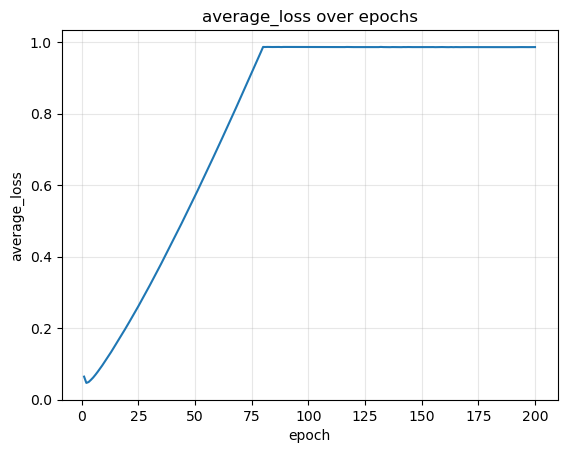

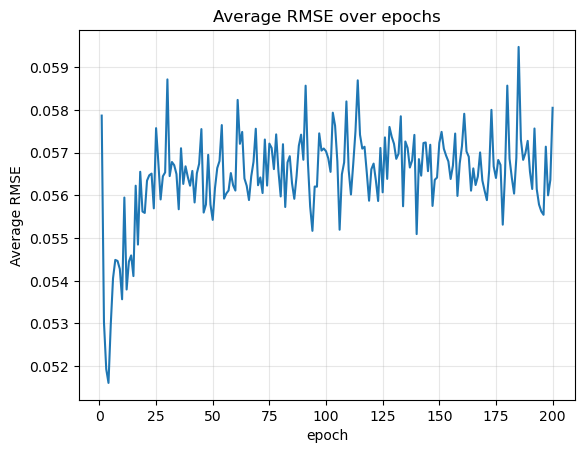

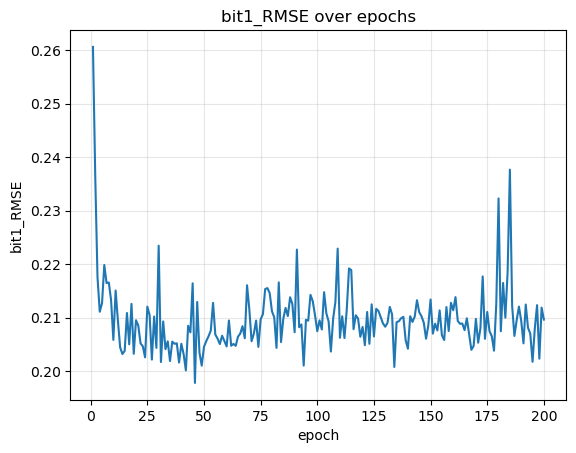

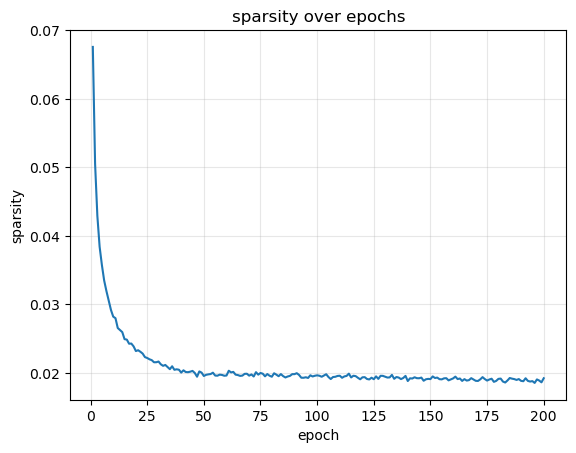

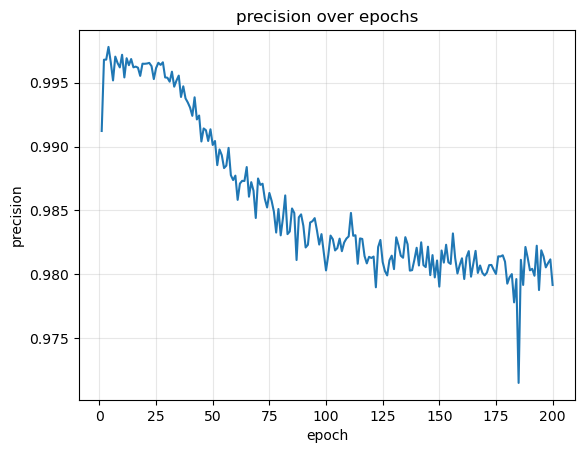

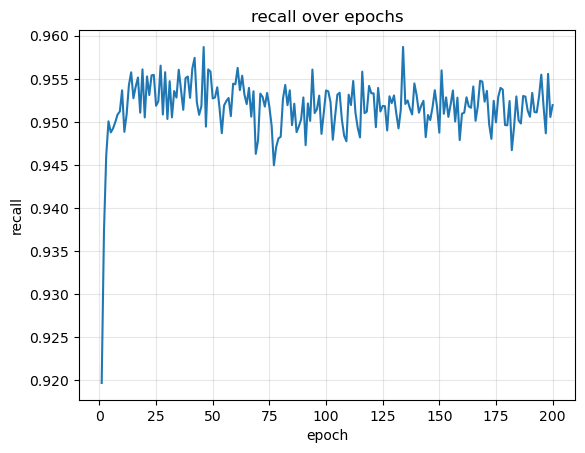


  Final Evaluation Metrics  (full dataset)
  RMSE               : 0.056807
  Bit=1 RMSE         : 0.209005
  Sparsity (|z| avg) : 0.018926
  Precision          : 0.9800
  Recall             : 0.9519
  Final epoch loss   : 0.986028



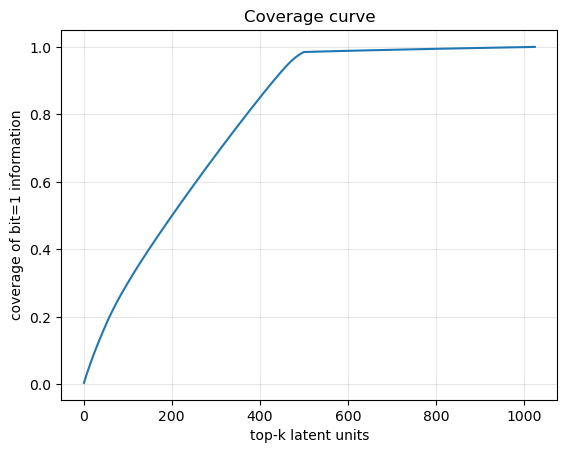

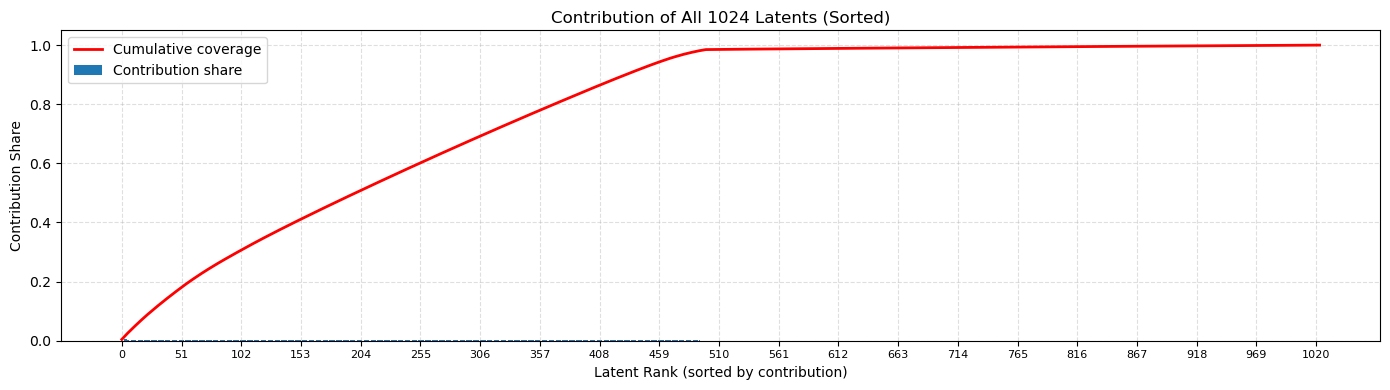


Top‑k latent coverage table:
  20% coverage → top‑59 latents
  50% coverage → top‑201 latents
  80% coverage → top‑371 latents
  90% coverage → top‑432 latents
  95% coverage → top‑466 latents
  99% coverage → top‑649 latents


In [7]:
# ===== Imports =====
from __future__ import annotations
import os, gc, random
from dataclasses import dataclass
from typing import List, Dict, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
import numpy as np
from tqdm import tqdm
from sklearn.metrics import precision_score, recall_score
import matplotlib.pyplot as plt

# -------------------------------------------------
# 0. Set random seed
# -------------------------------------------------

def set_seed(seed: int = 42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

# -------------------------------------------------
# 1. Configuration
# -------------------------------------------------
@dataclass(frozen=True)
class SAEConfig:
    device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    input_dim: int = 4096
    latent_dim: int = 1024

    # Training
    batch_size: int = 512
    epochs: int = 200
    learning_rate: float = 1e-3

    # Loss weights
    sparsity_lambda: float = 0.3
    decoder_weight_lambda: float = 1e-3
    specialization_lambda: float = 10.0
    reconstruction_priority: float = 3.0
    

    # Specialist‑initialisation
    n_specialists: int = 150
    specialist_conn_range: Tuple[int, int] = (5, 15)

    # Data paths
    csv_path: str = "../../dataset/LSAE/mol/chembl_morgan_matrix.csv"
    cache_path: str = "../../dataset/LSAE/mol/LSAE_chembl_1900k_preprocessed_data.pt"

# -------------------------------------------------
# 2. Data utilities
# -------------------------------------------------

def load_data(cfg: SAEConfig) -> TensorDataset:
    if os.path.exists(cfg.cache_path):
        data = torch.load(cfg.cache_path)
        data=data[:100000]
    else:
            chunk_size = 50000
            chunks = []
            for chunk_df in pd.read_csv(cfg.csv_path, chunksize=chunk_size, header=None, dtype='float32'):
                chunks.append(torch.tensor(chunk_df.values, dtype=torch.float32))    
            data = torch.cat(chunks, dim=0)
            torch.save(data, cfg.cache_path)
    return TensorDataset(data)

# -------------------------------------------------
# 3. Sparse Linear Auto‑encoder
# -------------------------------------------------
class SparseLinearAE(nn.Module):
    def __init__(self, cfg: SAEConfig):
        super().__init__()
        self.cfg = cfg
        self.encoder = nn.Linear(cfg.input_dim, cfg.latent_dim)
        self.decoder = nn.Linear(cfg.latent_dim, cfg.input_dim)
        self.specialization_weight: float = 0.0
        self._init_weights()

    def _init_weights(self):
        nn.init.xavier_uniform_(self.encoder.weight)
        nn.init.xavier_uniform_(self.decoder.weight)
        with torch.no_grad():
            n_spec = min(self.cfg.n_specialists, self.cfg.latent_dim)
            spec_idx = torch.randperm(self.cfg.latent_dim)[:n_spec]
            for idx in spec_idx:
                n_conn = torch.randint(*self.cfg.specialist_conn_range, (1,)).item()
                conn_idx = torch.randperm(self.cfg.input_dim)[:n_conn]
                scale = 2.0 / np.sqrt(n_conn)
                self.encoder.weight[idx, conn_idx] *= scale
                self.decoder.weight[conn_idx, idx] *= scale

    def forward(self, x):
        latent = self.encoder(x)
        recon = self.decoder(latent)
        return recon, latent

    # -------- Loss components --------
    def specialization_loss(self, x, latent):
        bit1 = (x == 1).float()
        if bit1.sum() == 0:
            return torch.tensor(0.0, device=x.device)
        avg_b1 = bit1.mean(dim=0)
        latent_abs = latent.abs().mean(dim=0)
        decoder_abs = self.decoder.weight.abs()
        affinity = latent_abs * torch.matmul(avg_b1, decoder_abs)
        sorted_aff, _ = torch.sort(affinity, descending=True)
        # concentration = sorted_aff[:100].sum() / (sorted_aff.sum() + 1e-8)
        # return torch.relu(0.7 - concentration) * 0.1

        top_k_primary,top_k_secondary, target_ratio_primary,target_ratio_secondary = 500,600, 0.99,0.993

        concentration_primary = sorted_aff[:top_k_primary].sum() / (sorted_aff.sum() + 1e-8)
        concentration_secondary = sorted_aff[:top_k_secondary].sum() / (sorted_aff.sum() + 1e-8)

        penalty_primary = F.softplus(target_ratio_primary - concentration_primary) * 0.1
        penalty_secondary = F.softplus(target_ratio_secondary - concentration_secondary) * 0.04


        max_share_limit = 0.03       
        penalty_max = F.relu(sorted_aff[0]/(sorted_aff.sum() + 1e-8) - max_share_limit) * 0.025
        penalty = penalty_primary + penalty_secondary + penalty_max

        return penalty
    

    def sparsity_loss(self, latent):
        mean_act = latent.abs().mean()
        l1_term = mean_act                      
        return l1_term  
    
    def weight_balance_loss(self):
        return self.decoder.weight.T.norm(dim=1).std()

    def total_loss(self, x, recon, latent):
        cfg = self.cfg
        alpha      = 3.0                     
        bit1_mask  = (x == 1).float()        
        recon_err  = F.mse_loss(recon, x, reduction='none')
        recon_loss = ((1 + alpha * bit1_mask) * recon_err).mean()
        sparsity = self.sparsity_loss(latent)
        balance = self.weight_balance_loss()
        spec = self.specialization_loss(x, latent)
        total = (cfg.reconstruction_priority * recon_loss +
                 cfg.sparsity_lambda * sparsity +
                 cfg.decoder_weight_lambda * balance +
                 self.specialization_weight * spec)
        return total, recon_loss.item(), sparsity.item(), balance.item(), spec.item()

# -------------------------------------------------
# 4. Metrics
# -------------------------------------------------

def compute_metrics(x, recon, latent):
    rmse = torch.sqrt(F.mse_loss(recon, x)).item()
    bit1_mask = (x == 1)
    bit1_rmse = torch.sqrt(F.mse_loss(recon[bit1_mask], x[bit1_mask])).item() if bit1_mask.sum() else 0.0
    sparsity_val = latent.abs().mean().item()
    x_np = x.cpu().numpy(); r_np = recon.detach().cpu().numpy()
    precision_val = precision_score(x_np.flatten() > 0.5, r_np.flatten() > 0.5, zero_division=0)
    recall_val = recall_score(x_np.flatten() > 0.5, r_np.flatten() > 0.5, zero_division=0)
    orig_feats = (x_np > 0).sum(axis=1)
    recon_feats = (r_np > 0.5).sum(axis=1)
    return rmse, bit1_rmse, sparsity_val, precision_val, recall_val

# -------------------------------------------------
# 5. Coverage
# -------------------------------------------------

def compute_topk_coverage(model: SparseLinearAE, loader: DataLoader):
    device = model.cfg.device
    latent_dim = model.cfg.latent_dim
    total_contrib = torch.zeros(latent_dim, device=device)
    dec_abs = model.decoder.weight.abs().to(device)
    with torch.no_grad():
        for xb, in loader:
            x = xb.to(device)
            _, latent = model(x)
            bit1_mask = (x == 1)
            if bit1_mask.sum() == 0:
                continue
            bit1_any = bit1_mask.any(dim=0)
            dec_strength = dec_abs[bit1_any, :].sum(dim=0)
            contrib = latent.abs() * dec_strength
            total_contrib += contrib.sum(dim=0)
    total_contrib /= total_contrib.sum()
    sorted_vals, sorted_idx = torch.sort(total_contrib, descending=True)
    cumulative = torch.cumsum(sorted_vals, 0)
    thresholds = [0.2, 0.5, 0.8, 0.9, 0.95, 0.99]
    table = {f"{int(t*100)}%": int((cumulative >= t).nonzero(as_tuple=False)[0].item()) + 1 for t in thresholds}
    return table, cumulative.cpu(),sorted_vals.cpu(),sorted_idx.cpu()

# -------------------------------------------------
# 6. Schedulers & plotting helpers
# -------------------------------------------------

def spec_schedule(epoch: int, cfg: SAEConfig, warm_epochs: int = 80) -> float:

    progress = min(epoch / warm_epochs, 1.0)          
    return cfg.specialization_lambda * (progress ** 1.2)


def plot_metric(history_epochs: List[int], values: List[float], name: str):
    plt.figure()
    plt.plot(history_epochs, values)
    plt.xlabel("epoch")
    plt.ylabel(name)
    plt.title(f"{name} over epochs")
    plt.grid(True, alpha=0.3)
    plt.show()


def plot_coverage(cumulative: torch.Tensor):
    plt.figure()
    plt.plot(range(1, len(cumulative)+1), cumulative.numpy())
    plt.xlabel("top‑k latent units")
    plt.ylabel("coverage of bit=1 information")
    plt.title("Coverage curve")
    plt.grid(True, alpha=0.3)
    plt.show()


def plot_topk_contrib_full(vals, idx):
    all_vals = vals.numpy()
    all_idx = idx.numpy()
    cumulative_vals = np.cumsum(all_vals)

    plt.figure(figsize=(14, 4))

    plt.bar(range(len(all_vals)), all_vals, label="Contribution share")

    # line chart cumulative attribution
    plt.plot(range(len(all_vals)), cumulative_vals, color='red', linewidth=2, label="Cumulative coverage")

    plt.title(f'Contribution of All {len(all_vals)} Latents (Sorted)')
    plt.xlabel('Latent Rank (sorted by contribution)')
    plt.ylabel('Contribution Share')
    plt.xticks(
        ticks=range(0, len(all_idx), max(len(all_idx)//20, 1)),
        labels=range(0, len(all_idx), max(len(all_idx)//20, 1)),
        rotation=0, fontsize=8
    )
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()


# -------------------------------------------------
# 7. Training
# -------------------------------------------------

def train(cfg: SAEConfig):
    dataset = load_data(cfg)
    g = torch.Generator()
    g.manual_seed(42)
    loader = DataLoader(dataset, batch_size=cfg.batch_size, shuffle=True, generator=g)
    model = SparseLinearAE(cfg).to(cfg.device)
    optim = torch.optim.Adam(model.parameters(), lr=cfg.learning_rate)

    # history containers
    epochs, losses, rmses, bit1_rmses, sparsities, precisions, recalls = ([] for _ in range(7))

    for epoch in range(1, cfg.epochs + 1):
        model.specialization_weight = spec_schedule(epoch, cfg)
        model.train(); running = 0.0
        for xb, in tqdm(loader, desc=f"Epoch {epoch}", leave=False):
            x = xb.to(cfg.device)
            optim.zero_grad(); recon, latent = model(x)
            total, *loss_parts = model.total_loss(x, recon, latent)
            total.backward(); optim.step()
            running += total.item() * x.size(0)
        avg_loss = running / len(loader.dataset)

        # quick metrics
        model.eval(); x_sample = next(iter(loader))[0].to(cfg.device)
        recon_s, latent_s = model(x_sample)
        rmse, bit1_rmse, spars, prec, rec = compute_metrics(x_sample, recon_s, latent_s)

        # store
        epochs.append(epoch); losses.append(avg_loss); rmses.append(rmse); bit1_rmses.append(bit1_rmse)
        sparsities.append(spars); precisions.append(prec); recalls.append(rec); 

    # plot metrics
    names_vals = [
        ("average_loss", losses),
        ("Average RMSE", rmses),
        ("bit1_RMSE", bit1_rmses),
        ("sparsity", sparsities),
        ("precision", precisions),
        ("recall", recalls)
    ]
    for n, v in names_vals:
        plot_metric(epochs, v, n)

    # -------- Final evaluation on full dataset --------
    model.eval()
    all_x, all_recon, all_latent = [], [], []
    eval_loader = DataLoader(dataset, batch_size=512, shuffle=False)
    with torch.no_grad():
        for xb, in eval_loader:
            x = xb.to(cfg.device)
            recon, latent = model(x)
            all_x.append(x)
            all_recon.append(recon)
            all_latent.append(latent)
    all_x     = torch.cat(all_x)
    all_recon = torch.cat(all_recon)
    all_latent = torch.cat(all_latent)

    f_rmse, f_bit1_rmse, f_spars, f_prec, f_rec = compute_metrics(
        all_x, all_recon, all_latent
    )

    print("\n" + "=" * 52)
    print("  Final Evaluation Metrics  (full dataset)")
    print("=" * 52)
    print(f"  RMSE               : {f_rmse:.6f}")
    print(f"  Bit=1 RMSE         : {f_bit1_rmse:.6f}")
    print(f"  Sparsity (|z| avg) : {f_spars:.6f}")
    print(f"  Precision          : {f_prec:.4f}")
    print(f"  Recall             : {f_rec:.4f}")
    print(f"  Final epoch loss   : {losses[-1]:.6f}")
    print("=" * 52 + "\n")

    # coverage
    cov_loader = DataLoader(dataset, batch_size=512, shuffle=False)
    table, cumulative,vals,idx = compute_topk_coverage(model, cov_loader)
    plot_coverage(cumulative)
    plot_topk_contrib_full(vals, idx)

    print("\nTop‑k latent coverage table:")
    for k, v in table.items():
        print(f"  {k} coverage → top‑{v} latents")

    # ------- after compute_topk_coverage -------
    threshold = 0.99
    k99 = int((cumulative >= threshold).nonzero()[0].item()) + 1
    keep_idx_99 = idx[:k99].cpu()           # tensor shape [k99],the top can be further selected

    # save
    torch.save(keep_idx_99, "./LSAE_chembl_1900k_topk_of1024d_top99_2.pt")

    torch.save(model.state_dict(), "./LSAE_1900k_chembl_model_2.pt")
    del model, optim, dataset, loader
    torch.cuda.empty_cache(); gc.collect()

# -------------------------------------------------
# 8. Entry
# -------------------------------------------------
if __name__ == "__main__":
    set_seed(42)
    cfg = SAEConfig()
    train(cfg)
